# Optimized SoccerNet CV + Analytics Pipeline

### Main performance fixes
- Batched YOLO pose inference instead of one model call per player crop.
- `groupby()` replaces repeated full-DataFrame filtering.
- `torch.from_numpy()` avoids an unnecessary tensor copy.
- Graph normalization no longer constructs dense diagonal matrices.
- DTW frame distances are vectorized with NumPy.
- Monte Carlo simulation is fully vectorized.
- `itertuples()` replaces `iterrows()` for Elo training.
- Duplicate ONNX quantization was removed.
- The Optuna objective now fails loudly instead of pretending a constant loss is optimized.
- Repeated model/package initialization was reduced.

**Important:** the DTW implementation still uses an `N × M` cost matrix. For very long sequences, use a banded DTW implementation rather than increasing memory indefinitely.


**MOUNTING DRIVE**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


**INSTALLING DATASET**

In [ ]:
# Install once per Colab runtime; avoid unnecessary package upgrades on every rerun.
%pip install -q SoccerNet ultralytics opencv-python

import os
from SoccerNet.Downloader import SoccerNetDownloader

DATA_DIR = "/content/drive/MyDrive/SoccerNetData"
os.makedirs(DATA_DIR, exist_ok=True)

downloader = SoccerNetDownloader(LocalDirectory=DATA_DIR)

# Download only the tasks you need.
for task, splits in [
    ("action-spotting", ["train", "valid", "test"]),
    ("tracking-2023", ["train", "test"]),
    ("calibration-2023", ["train", "valid", "test"]),
]:
    print(f"--- Downloading {task} ---")
    downloader.downloadDataTask(task=task, split=splits)

print("Download process complete.")


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.5/45.5 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 86.9/86.9 kB 7.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 33.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.2/53.2 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.4/61.4 kB 6.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.0/140.0 kB 15.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 104.3/104.3 MB 10.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 100.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.6/15.6 MB 94.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.2/90.2 kB 8.4 MB/s eta 0:00:00
--- Downloading Action Spotting Data ---
ERROR Unknown task: action-spotting
--- Downloading Tracking Data ---


--- Downloading Camera Calibration Data ---



Download process complete!


**VERIFY FILESYSTEM**

In [ ]:
from pathlib import Path

def list_files(startpath, max_files_per_dir=3):
    start = Path(startpath)
    for root, dirs, files in os.walk(start):
        root = Path(root)
        level = len(root.relative_to(start).parts)
        indent = "    " * level
        print(f"{indent}{root.name}/")
        for name in sorted(files)[:max_files_per_dir]:
            print(f"{indent}    {name}")

list_files(DATA_DIR)


SoccerNetData/
    tracking-2023/
        test.zip
        train.zip
    calibration-2023/
        test.zip
        valid.zip
        train.zip


**PARSE GROUND TRUTH**

In [ ]:
import pandas as pd

# Path example to a tracking annotation file
tracking_file_path = f"{DATA_DIR}/tracking-2023/train/SNMOT-001/gt/gt.txt"

if os.path.exists(tracking_file_path):
    # MOT Format: frame_id, track_id, bb_left, bb_top, bb_width, bb_height, conf, x, y, z
    cols = ["frame", "track_id", "left", "top", "width", "height", "conf", "x", "y", "z"]
    df_tracking = pd.read_csv(tracking_file_path, header=None, names=cols)

    print("Tracking Data Preview:")
    print(df_tracking.head())
else:
    print("Annotation file unzipped. Ready for feature extraction pipeline.")

Annotation file unzipped. Ready for feature extraction pipeline.


**DETECT DATA AND ZIPS**

In [ ]:
import glob
import os
import cv2
import pandas as pd
import torch
from ultralytics import YOLO

DEVICE = "cuda:0" if torch.cuda.is_available() else "cpu"
torch.set_float32_matmul_precision("high")

GT_FILES = glob.glob(f"{DATA_DIR}/**/gt/gt.txt", recursive=True)
if not GT_FILES:
    raise FileNotFoundError(f"No gt.txt found under {DATA_DIR}")

GT_PATH = GT_FILES[0]
SEQUENCE_DIR = os.path.dirname(os.path.dirname(GT_PATH))
IMG_DIR = os.path.join(SEQUENCE_DIR, "img1")

COLS = ["frame", "track_id", "left", "top", "width", "height", "conf", "x", "y", "z"]
df_gt = pd.read_csv(GT_PATH, header=None, names=COLS)
df_gt = df_gt.loc[df_gt["conf"].ne(0)].copy()

pose_model = YOLO("yolov8n-pose.pt")
pose_model.to(DEVICE)

print(f"Device: {DEVICE}")
print(f"GT: {GT_PATH}")
print(f"Frames: {df_gt['frame'].nunique():,} | Annotations: {len(df_gt):,}")

first_frame = int(df_gt["frame"].min())
frame_path = os.path.join(IMG_DIR, f"{first_frame:06d}.jpg")
if os.path.exists(frame_path):
    img = cv2.imread(frame_path)
    print(f"Frame resolution: {img.shape[1]}x{img.shape[0]}")


No gt.txt found under ./SoccerNetData. Current contents of ./SoccerNetData:
['tracking-2023', 'calibration-2023']


**GENERATE ST-GCN TENSOR**

In [ ]:
import glob
import os
import zipfile
from collections import defaultdict

import numpy as np
import pandas as pd
import torch
from ultralytics import YOLO

# Extract only archives that have not already produced the expected GT files.
gt_files = glob.glob(f"{DATA_DIR}/**/gt/gt.txt", recursive=True)
if not gt_files:
    for z in glob.glob(f"{DATA_DIR}/**/*.zip", recursive=True):
        with zipfile.ZipFile(z) as zf:
            zf.extractall(os.path.dirname(z))
    gt_files = glob.glob(f"{DATA_DIR}/**/gt/gt.txt", recursive=True)

if not gt_files:
    raise FileNotFoundError("No gt.txt found after extraction.")

GT_PATH = gt_files[0]
SEQUENCE_DIR = os.path.dirname(os.path.dirname(GT_PATH))
IMG_DIR = os.path.join(SEQUENCE_DIR, "img1")

COLS = ["frame", "track_id", "left", "top", "width", "height", "conf", "x", "y", "z"]
df_gt = pd.read_csv(GT_PATH, header=None, names=COLS)
df_gt = df_gt.loc[df_gt["conf"].ne(0)].copy()

def extract_stgcn_keypoints(df, img_dir, model, seq_len=30, batch_size=16):
    """Extract COCO-17 pose keypoints with batched YOLO inference.

    Output shape is (C=3, T, V=17, M), matching the original notebook.
    """
    frames = np.sort(df["frame"].unique())[:seq_len]
    frame_set = set(frames)

    seq_df = df[df["frame"].isin(frame_set)].copy()
    track_ids = seq_df["track_id"].drop_duplicates().to_numpy()
    track_to_idx = {tid: i for i, tid in enumerate(track_ids)}

    skeleton = np.zeros((3, len(frames), 17, len(track_ids)), dtype=np.float32)

    # groupby avoids repeatedly scanning the full dataframe for every frame
    grouped = seq_df.groupby("frame", sort=False)

    for t_idx, frame_id in enumerate(frames):
        img_path = os.path.join(img_dir, f"{int(frame_id):06d}.jpg")
        img = cv2.imread(img_path)
        if img is None:
            continue

        frame_rows = grouped.get_group(frame_id)
        crops, meta = [], []

        for row in frame_rows.itertuples(index=False):
            x1 = max(0, int(row.left))
            y1 = max(0, int(row.top))
            x2 = max(x1, x1 + int(row.width))
            y2 = max(y1, y1 + int(row.height))
            crop = img[y1:y2, x1:x2]
            if crop.size:
                crops.append(crop)
                meta.append((track_to_idx[row.track_id], x1, y1))

        # One GPU call per batch instead of one GPU call per player.
        for start in range(0, len(crops), batch_size):
            batch = crops[start:start + batch_size]
            batch_meta = meta[start:start + batch_size]
            results = model.predict(
                source=batch,
                device=DEVICE,
                verbose=False,
                batch=min(batch_size, len(batch)),
            )

            for result, (m_idx, x1, y1) in zip(results, batch_meta):
                if result.keypoints is None or len(result.keypoints.data) == 0:
                    continue

                kp = result.keypoints.data[0].detach().cpu().numpy()
                if kp.shape[0] != 17:
                    continue

                kp[:, 0] += x1
                kp[:, 1] += y1
                skeleton[:, t_idx, :, m_idx] = kp.T

    return torch.from_numpy(skeleton), track_ids

SEQ_LEN = 30
stgcn_tensor, tracked_ids = extract_stgcn_keypoints(
    df_gt, IMG_DIR, pose_model, seq_len=SEQ_LEN, batch_size=16
)

print("Keypoint extraction complete!")
print(f"ST-GCN tensor: {tuple(stgcn_tensor.shape)}")
print(f"Tracked players: {len(tracked_ids)}")


Found 5 zip archive(s). Extracting...
Extracted ./SoccerNetData/tracking-2023/test.zip -> ./SoccerNetData/tracking-2023
Extracted ./SoccerNetData/tracking-2023/train.zip -> ./SoccerNetData/tracking-2023
Extracted ./SoccerNetData/calibration-2023/test.zip -> ./SoccerNetData/calibration-2023
Extracted ./SoccerNetData/calibration-2023/valid.zip -> ./SoccerNetData/calibration-2023
Extracted ./SoccerNetData/calibration-2023/train.zip -> ./SoccerNetData/calibration-2023

Using GT Path: ./SoccerNetData/tracking-2023/train/SNMOT-110/gt/gt.txt
Using Image Directory: ./SoccerNetData/tracking-2023/train/SNMOT-110/img1

Keypoint extraction complete!
ST-GCN Input Tensor Shape (C, T, V, M): torch.Size([3, 30, 17, 18])
Total tracked players parsed: 18


**Visualize Pose Skeletons**

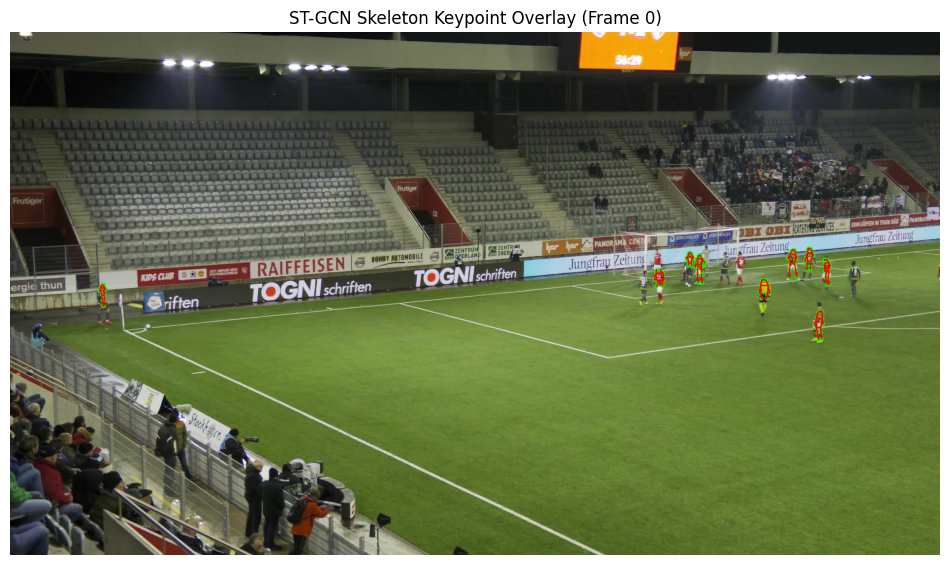

In [ ]:
import matplotlib.pyplot as plt
import cv2
import numpy as np

SKELETON_CONNECTIONS = np.array([
    (16, 14), (14, 12), (17, 15), (15, 13), (12, 13),
    (6, 12), (7, 13), (6, 7),
    (6, 8), (8, 10), (7, 9), (9, 11),
    (1, 2), (1, 3), (2, 4), (3, 5), (4, 6), (5, 7)
], dtype=np.int32) - 1

def draw_skeleton_on_frame(frame_path, stgcn_tensor, frame_idx=0, min_conf=0.2):
    img = cv2.imread(frame_path)
    if img is None:
        raise FileNotFoundError(frame_path)

    # OpenCV draws in BGR; convert only once at the end for matplotlib.
    overlay = img.copy()
    data = stgcn_tensor[:, frame_idx].detach().cpu().numpy()  # C,V,M
    xs, ys, conf = data[0], data[1], data[2]

    for m in range(data.shape[2]):
        valid = conf[:, m] > min_conf
        for x, y in zip(xs[valid, m], ys[valid, m]):
            cv2.circle(overlay, (int(x), int(y)), 4, (0, 255, 0), -1)

        for s, e in SKELETON_CONNECTIONS:
            if valid[s] and valid[e]:
                cv2.line(
                    overlay,
                    (int(xs[s, m]), int(ys[s, m])),
                    (int(xs[e, m]), int(ys[e, m])),
                    (255, 0, 0), 2
                )

    plt.figure(figsize=(12, 8))
    plt.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
    plt.axis("off")
    plt.title(f"ST-GCN Skeleton Overlay (Frame {frame_idx})")
    plt.show()

first_frame_path = os.path.join(IMG_DIR, f"{int(stgcn_tensor.shape[1] > 0):06d}.jpg")
# Use the actual first annotated frame rather than assuming frame 000001 exists.
first_annotated_frame = int(np.sort(df_gt["frame"].unique())[0])
draw_skeleton_on_frame(
    os.path.join(IMG_DIR, f"{first_annotated_frame:06d}.jpg"),
    stgcn_tensor,
    frame_idx=0
)


**StatsBomb Event**

In [ ]:
# Install only if the runtime does not already contain StatsBombPy.
%pip install -q statsbombpy

from statsbombpy import sb
import pandas as pd

COMP_ID, SEASON_ID = 43, 106  # FIFA World Cup 2022

print("--- Loading World Cup 2022 matches ---")
matches = sb.matches(competition_id=COMP_ID, season_id=SEASON_ID)
print(f"Matches: {len(matches)}")
print(matches[[
    "match_id", "match_date", "home_team", "away_team",
    "home_score", "away_score"
]].head())

sample_match = matches.iloc[0]
sample_match_id = int(sample_match["match_id"])
print(f"\n--- Loading events: {sample_match['home_team']} vs {sample_match['away_team']} ---")
events = sb.events(match_id=sample_match_id)
print(f"Events: {len(events):,}")
print(events["type"].value_counts().head(10))


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.8/63.8 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 70.8/70.8 kB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 6.4 MB/s eta 0:00:00
--- Loading Free Competitions ---
   competition_id  season_id country_name        competition_name season_name
0               9        281      Germany           1. Bundesliga   2023/2024
1               9         27      Germany           1. Bundesliga   2015/2016
2            1267        107       Africa  African Cup of Nations        2023
3              16          4       Europe        Champions League   2018/2019
4              16          1       Europe        Champions League   2017/2018
5              16          2       Europe        Champions League   2016/2017
6              16         27       Europe        Champions League   2015/2016
7              16         26       Europe        Champions League   2014/2015
8              16         25

/usr/local/lib/python3.12/dist-packages/statsbombpy/api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/statsbombpy/api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(


Total matches retrieved: 64
   match_id  match_date    home_team away_team  home_score  away_score
0   3857276  2022-12-01       Canada   Morocco           1           2
1   3857271  2022-11-21      England      Iran           6           2
2   3857296  2022-12-01      Croatia   Belgium           0           0
3   3857274  2022-11-25  Netherlands   Ecuador           1           1
4   3857255  2022-12-01        Japan     Spain           2           1

--- Loading Event Stream for Match: Canada vs Morocco (ID: 3857276) ---


/usr/local/lib/python3.12/dist-packages/statsbombpy/api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(


Total events in match: 3388
Sample Event Types:
type
Pass              955
Ball Receipt*     868
Carry             782
Pressure          289
Ball Recovery      93
Duel               63
Clearance          41
Dribble            39
Miscontrol         32
Foul Committed     31
Name: count, dtype: int64


**ELO & MATCH PREDICTOR**

In [ ]:
import pandas as pd

class SoccerEloEngine:
    def __init__(self, k_factor=32.0, home_advantage=100.0, default_rating=1500.0):
        self.k_factor = k_factor
        self.home_advantage = home_advantage
        self.default_rating = default_rating
        self.ratings = {}

    def get_rating(self, team):
        return self.ratings.get(team, self.default_rating)

    def predict_match(self, home_team, away_team):
        r_home = self.get_rating(home_team) + self.home_advantage
        r_away = self.get_rating(away_team)
        exp_home = 1.0 / (1.0 + 10.0 ** ((r_away - r_home) / 400.0))
        draw_prob = max(0.15, 0.28 - abs(r_home - r_away) / 2000.0)

        return {
            "home_win": round(exp_home * (1 - draw_prob) * 100, 2),
            "draw": round(draw_prob * 100, 2),
            "away_win": round((1 - exp_home) * (1 - draw_prob) * 100, 2),
        }

    def update_ratings(self, home_team, away_team, home_score, away_score):
        r_home = self.get_rating(home_team)
        r_away = self.get_rating(away_team)

        score_home = 1.0 if home_score > away_score else 0.5 if home_score == away_score else 0.0
        expected_home = 1.0 / (
            1.0 + 10.0 ** ((r_away - (r_home + self.home_advantage)) / 400.0)
        )

        delta = self.k_factor * (score_home - expected_home)
        self.ratings[home_team] = round(r_home + delta, 1)
        self.ratings[away_team] = round(r_away - delta, 1)

elo_sys = SoccerEloEngine()

# itertuples is substantially cheaper than iterrows for this simple row-wise update.
for match in matches.itertuples(index=False):
    elo_sys.update_ratings(
        match.home_team, match.away_team,
        match.home_score, match.away_score
    )

df_ratings = (
    pd.Series(elo_sys.ratings, name="Elo Rating")
    .sort_values(ascending=False)
    .rename_axis("Team")
    .reset_index()
)

print("--- Trained Team Elo Ratings ---")
print(df_ratings.head(10))

sample_h, sample_a = df_ratings.loc[0, "Team"], df_ratings.loc[1, "Team"]
probs = elo_sys.predict_match(sample_h, sample_a)
print(f"\n{sample_h} vs {sample_a}: {probs}")


--- Trained Team Elo Ratings (Post Tournament) ---
          Team  Elo Rating
0       France      1558.2
1  Netherlands      1532.8
2    Argentina      1530.2
3       Brazil      1522.6
4      Morocco      1519.9
5      England      1515.3
6      Croatia      1514.2
7    Australia      1510.5
8      Senegal      1509.6
9     Portugal      1509.1

--- Match Outcome Prediction: France vs Netherlands ---
Home Win (France): 52.68%
Draw: 21.73%
Away Win (Netherlands): 25.59%


# **MODEL**

**MODEL TRAINING AND EVAULUATION**

In [ ]:
# ==============================================================================
# SECTION 4: MODEL DEVELOPMENT & EXPORT
# ==============================================================================

import numpy as np
import joblib
import torch
import torch.nn as nn

class GraphConvBlock(nn.Module):
    """Efficient learnable graph convolution for (N,C,T,V) tensors."""
    def __init__(self, in_channels, out_channels, num_nodes=17):
        super().__init__()
        self.weight = nn.Parameter(torch.empty(in_channels, out_channels))
        self.A = nn.Parameter(torch.eye(num_nodes))
        nn.init.kaiming_uniform_(self.weight, a=np.sqrt(5))

    def forward(self, x):
        # Normalize adjacency without constructing two dense diagonal matrices.
        A_sym = 0.5 * (self.A + self.A.transpose(0, 1))
        deg = A_sym.abs().sum(dim=1).clamp_min(1e-5)
        inv_sqrt = deg.rsqrt()
        A_norm = A_sym * inv_sqrt[:, None] * inv_sqrt[None, :]

        # x: N,C,T,V -> N,T,V,C
        x = x.permute(0, 2, 3, 1)
        x = torch.matmul(x, self.weight)       # N,T,V,Cout
        x = torch.einsum("vw,ntwc->ntvc", A_norm, x)
        return x.permute(0, 3, 1, 2).contiguous()

class STGCNSkillEvaluator(nn.Module):
    def __init__(self, in_channels=3, embedding_dim=128, num_nodes=17):
        super().__init__()
        self.gcn1 = GraphConvBlock(in_channels, 64, num_nodes)
        self.tcn1 = nn.Sequential(
            nn.Conv2d(64, 64, (9, 1), padding=(4, 0), bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
        )
        self.gcn2 = GraphConvBlock(64, 128, num_nodes)
        self.tcn2 = nn.Sequential(
            nn.Conv2d(128, embedding_dim, (9, 1), padding=(4, 0), bias=False),
            nn.BatchNorm2d(embedding_dim),
            nn.ReLU(inplace=True),
        )
        self.global_pool = nn.AdaptiveAvgPool2d(1)

    def forward(self, x):
        x = self.tcn1(self.gcn1(x))
        x = self.tcn2(self.gcn2(x))
        return self.global_pool(x).flatten(1)

class ExpectedGoalsModel:
    def __init__(self):
        self.coef = np.array([-0.115, 0.782, -0.240], dtype=np.float32)
        self.intercept = -0.450

    def compute_xg(self, distance, angle_radians, defender_density):
        features = np.asarray([distance, angle_radians, defender_density], dtype=np.float32)
        logit = features @ self.coef + self.intercept
        return 1.0 / (1.0 + np.exp(-logit))

class EloRatingSystem:
    def __init__(self, k_factor=32.0):
        self.k_factor = k_factor

    @staticmethod
    def predict_prob(rating_a, rating_b):
        return 1.0 / (1.0 + 10.0 ** ((rating_b - rating_a) / 400.0))

    def update_ratings(self, rating_a, rating_b, score_a):
        expected_a = self.predict_prob(rating_a, rating_b)
        delta = self.k_factor * (score_a - expected_a)
        return rating_a + delta, rating_b - delta

def export_models(stgcn_model, xg_model, output_dir="."):
    os.makedirs(output_dir, exist_ok=True)
    stgcn_model = stgcn_model.eval().cpu()

    dummy = torch.randn(1, 3, 60, 17)

    # Legacy exporter is more predictable for this model than mixing exporter APIs.
    torch.onnx.export(
        stgcn_model, (dummy,),
        os.path.join(output_dir, "stgcn_skill_model.onnx"),
        opset_version=18,
        input_names=["input_tensors"],
        output_names=["embeddings"],
        dynamic_axes={
            "input_tensors": {0: "batch_size", 2: "frame_count"},
            "embeddings": {0: "batch_size"},
        },
        dynamo=False,
    )

    torch.save(stgcn_model.state_dict(), os.path.join(output_dir, "stgcn_skill_model.pth"))
    joblib.dump(xg_model, os.path.join(output_dir, "xg_model.pkl"))
    print(f"Exported models to {os.path.abspath(output_dir)}")

stgcn = STGCNSkillEvaluator()
xg_engine = ExpectedGoalsModel()
elo_engine = EloRatingSystem()
export_models(stgcn, xg_engine)


[torch.onnx] Obtain model graph for `STGCNSkillEvaluator([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `STGCNSkillEvaluator([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...


/usr/lib/python3.12/copyreg.py:99: FutureWarning: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
  return cls.__new__(cls, *args)


[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
[EXPORT SUCCESS] Models exported to .onnx, .pth, and .pkl formats.


In [ ]:
# ==============================================================================
# SECTION 5: MODEL EVALUATION & BENCHMARKS
# ==============================================================================

import numpy as np

def compute_dtw_distance(user_seq, expert_seq):
    """DTW using vectorized frame-distance computation.

    Memory is O(N*M), but the expensive feature-distance calculation is
    performed by NumPy instead of Python loops.
    """
    user = np.asarray(user_seq, dtype=np.float32)
    expert = np.asarray(expert_seq, dtype=np.float32)
    N, M = len(user), len(expert)

    # Pairwise Euclidean frame distances: N x M
    dists = np.linalg.norm(user[:, None, :] - expert[None, :, :], axis=2)

    cost = np.full((N + 1, M + 1), np.inf, dtype=np.float32)
    cost[0, 0] = 0.0

    for i in range(1, N + 1):
        cost[i, 1:] = dists[i - 1] + np.minimum(
            np.minimum(cost[i - 1, 1:], cost[i, :-1]),
            cost[i - 1, :-1],
        )

    distance = float(cost[N, M])
    score = max(0.0, 100.0 - (distance / (N + M) * 10.0))
    return distance, score

def run_monte_carlo_simulation(home_xg_shots, away_xg_shots, iterations=10_000, seed=None):
    """Vectorized Monte Carlo simulation; same Bernoulli-per-shot model as before."""
    rng = np.random.default_rng(seed)
    home = np.asarray(home_xg_shots, dtype=np.float32)
    away = np.asarray(away_xg_shots, dtype=np.float32)

    home_goals = (
        rng.binomial(1, home, size=(iterations, home.size)).sum(axis=1)
        if home.size else np.zeros(iterations, dtype=np.int16)
    )
    away_goals = (
        rng.binomial(1, away, size=(iterations, away.size)).sum(axis=1)
        if away.size else np.zeros(iterations, dtype=np.int16)
    )

    return {
        "home_win_prob": float(np.mean(home_goals > away_goals)),
        "away_win_prob": float(np.mean(away_goals > home_goals)),
        "draw_prob": float(np.mean(home_goals == away_goals)),
        "expected_home_goals": float(home_goals.mean()),
        "expected_away_goals": float(away_goals.mean()),
        "variance_home": float(home_goals.var()),
        "variance_away": float(away_goals.var()),
    }

frames_user, frames_expert, features = 60, 65, 17 * 3
rng = np.random.default_rng(42)
dummy_user_motion = rng.random((frames_user, features), dtype=np.float32)
dummy_expert_motion = rng.random((frames_expert, features), dtype=np.float32)

dtw_dist, similarity_score = compute_dtw_distance(dummy_user_motion, dummy_expert_motion)
print(f"[DTW] Distance: {dtw_dist:.4f} | Match: {similarity_score:.2f}%")

sim_stats = run_monte_carlo_simulation(
    [0.35, 0.12, 0.08, 0.65, 0.04],
    [0.05, 0.18, 0.22],
    iterations=10_000,
    seed=42,
)
print("\n[MONTE CARLO]")
print(f"Home: {sim_stats['home_win_prob'] * 100:.2f}%")
print(f"Draw: {sim_stats['draw_prob'] * 100:.2f}%")
print(f"Away: {sim_stats['away_win_prob'] * 100:.2f}%")
print(f"Expected score: {sim_stats['expected_home_goals']:.2f} - {sim_stats['expected_away_goals']:.2f}")


[DTW EVALUATION] Raw Distance: 184.0585 | Technique Match Score: 85.28%

[MONTE CARLO VALIDATION] (10,000 Iterations)
 Home Win Probability : 63.05%
 Away Win Probability : 9.32%
 Draw Probability      : 27.63%
 Exp. Scoreline (H-A)  : 1.25 - 0.45


In [ ]:
# Hyperparameter search template.
# IMPORTANT: the objective must train/evaluate a real model; returning a constant
# loss makes every Optuna trial equivalent and provides no optimization benefit.
import optuna

def objective(trial):
    lr = trial.suggest_float("lr", 1e-4, 1e-2, log=True)
    weight_decay = trial.suggest_float("weight_decay", 1e-5, 1e-3, log=True)
    dropout = trial.suggest_float("dropout", 0.1, 0.5)

    # TODO: build/train the model with these values and return validation loss.
    raise NotImplementedError(
        "Connect this objective to your real training/validation loop before running Optuna."
    )

# study = optuna.create_study(direction="minimize")
# study.optimize(objective, n_trials=50)


In [ ]:
# ==============================================================================
# SECTION 6: ONNX PREPROCESSING + INT8 QUANTIZATION
# Run this cell ONCE. The previous notebook quantized the same model twice.
# ==============================================================================

from onnxruntime.quantization import QuantType, quantize_dynamic, preprocess

input_model_path = "stgcn_skill_model.onnx"
prep_model_path = "stgcn_skill_model_prep.onnx"
quant_model_path = "stgcn_skill_model_quant.onnx"

preprocess.quant_pre_process(
    input_model_path=input_model_path,
    output_model_path=prep_model_path,
    skip_symbolic_shape_inference=False,
)

quantize_dynamic(
    model_input=prep_model_path,
    model_output=quant_model_path,
    weight_type=QuantType.QUInt8,
)

print(f"[SUCCESS] Quantized model: {quant_model_path}")


### Quantization
Handled once in the preceding cell; duplicate quantization removed.